# Qwen3_small: deliverables

Each section maps to one line of the task specification, in order. Everything is read from the
final training runs in `runs/final/` and the classifier runs in `runs/cls/`; the reasoning behind
each choice is in `DECISIONS.md`, and the experiments that led to it are in `report.ipynb`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from generate import SPEC_PROMPTS, SPEC_TEMPERATURES, format_generations, load_model
from qwen3_small.config import QWEN_CONFIG_06_B
from qwen3_small.data import get_tokenizer, load_split

RUNS = Path("runs")
finals = {p.parent.name: json.loads(p.read_text()) for p in sorted((RUNS / "final").glob("*/summary.json"))}
best_name = min(finals, key=lambda k: finals[k]["full_val_loss"])
BEST = RUNS / "final" / best_name
cfg_run = json.loads((BEST / "config.json").read_text())
print("final runs:", list(finals), "| selected:", best_name)

final runs: ['adamw', 'muon'] | selected: muon


## 1. Modify the reference Qwen3 into a "Qwen3_small" of ~100–200M parameters

`qwen3_small/model.py` is the reference `standalone-qwen3.ipynb` code (same classes:
`Qwen3Model`, `TransformerBlock`, `GroupedQueryAttention`, `FeedForward`, `RMSNorm`,
`compute_rope_params`, `apply_rope`), with the configuration changed and tied embeddings,
fused SDPA attention and residual dropout added. Below: the config next to the original 0.6B.

In [2]:
small = cfg_run["cfg"]
keys = [k for k in QWEN_CONFIG_06_B if k != "dtype"] + [k for k in small if k not in QWEN_CONFIG_06_B]
pd.DataFrame({"Qwen3-0.6B (reference)": [QWEN_CONFIG_06_B.get(k, "—") for k in keys],
              "Qwen3_small (ours)": [small.get(k, "—") for k in keys]}, index=keys)

,Qwen3-0.6B (reference),Qwen3_small (ours)
vocab_size,151936,8192
context_length,40960,512
emb_dim,1024,640
n_heads,16,10
n_layers,28,24
hidden_dim,3072,1728
head_dim,128,64
qk_norm,True,True
n_kv_groups,8,5
rope_base,1000000.0,10000.0


In [3]:
p = cfg_run["params"]
print(f"total parameters (tied, counted once): {p['total']:,}  ->  {p['total'] / 1e6:.1f}M")
print(f"  token embedding / LM head (tied):    {p['embedding']:,}")
print(f"  transformer blocks + final norm:     {p['non_embedding']:,}")
assert 100e6 <= p["total"] <= 200e6

total parameters (tied, counted once): 114,394,752  ->  114.4M
  token embedding / LM head (tied):    5,242,880
  transformer blocks + final norm:     109,151,872


## 2. Tokenizer

Byte-level BPE with an 8,192-token vocabulary, trained on the training split only (see `DECISIONS.md` §2).

In [4]:
tok = get_tokenizer(cfg_run["args"]["vocab"])
s = "once upon a time, there was a little girl named lily. she loved to play outside."
ids = tok.encode(s)
print(f"vocab size {tok.vocab_size}; {len(s.split())} words -> {len(ids)} tokens")
print([tok.decode([i]) for i in ids])
assert tok.decode(ids) == s

vocab size 8192; 16 words -> 19 tokens
['once', ' upon', ' a', ' time', ',', ' there', ' was', ' a', ' little', ' girl', ' named', ' lily', '.', ' she', ' loved', ' to', ' play', ' outside', '.']


## 3. Data: a TinyStories subset with a 90% / 10% split

In [5]:
train, val = load_split(cfg_run["args"]["stories"])
print(f"{len(train) + len(val):,} stories -> {len(train):,} train ({len(train) / (len(train) + len(val)):.0%}) / {len(val):,} validation")
print(f"stories in both splits: {len(set(train) & set(val))}")
d = cfg_run["data"]
print(f"train tokens {d['train_tokens']:,} | validation tokens {d['val_tokens']:,}")

50,000 stories -> 45,000 train (90%) / 5,000 validation
stories in both splits: 0
train tokens 9,711,328 | validation tokens 1,085,183


## 4. The loss decreasing step by step, through validation steps

`train.py` logs the training loss at every optimizer step and the validation loss every
100 steps; below is an excerpt of that log and the full curves.

In [6]:
rows = [json.loads(l) for l in open(BEST / "metrics.jsonl")]
tr = pd.DataFrame([r for r in rows if r.get("train_loss") is not None])
va = pd.DataFrame([r for r in rows if "val_loss" in r])
val_at = dict(zip(va.step, va.val_loss))
for r in tr[tr.step <= 205].itertuples():
    if r.step <= 10 or r.step % 25 == 0:
        print(f"step {r.step:5d} | train loss {r.train_loss:.4f}")
    if r.step in val_at:
        print(f"step {r.step:5d} | val loss   {val_at[r.step]:.4f}   <- validation")
print("...")
print(f"{len(va)} validation evaluations; first {va.val_loss.iloc[0]:.4f} -> best {va.val_loss.min():.4f} (step {int(va.step[va.val_loss.idxmin()])})")

step     1 | train loss 9.1174
step     2 | train loss 9.1083
step     3 | train loss 9.0722
step     4 | train loss 9.0192
step     5 | train loss 8.9415
step     6 | train loss 8.8689
step     7 | train loss 8.7594
step     8 | train loss 8.6055
step     9 | train loss 8.4556
step    10 | train loss 8.2749
step    25 | train loss 5.5642
step    50 | train loss 4.1868
step    75 | train loss 3.6776
step   100 | train loss 3.3515
step   100 | val loss   3.3594   <- validation
step   125 | train loss 3.1581
step   150 | train loss 2.8565
step   175 | train loss 2.6625
step   200 | train loss 2.6805
step   200 | val loss   2.6522   <- validation
...
61 validation evaluations; first 9.1301 -> best 1.5872 (step 5920)


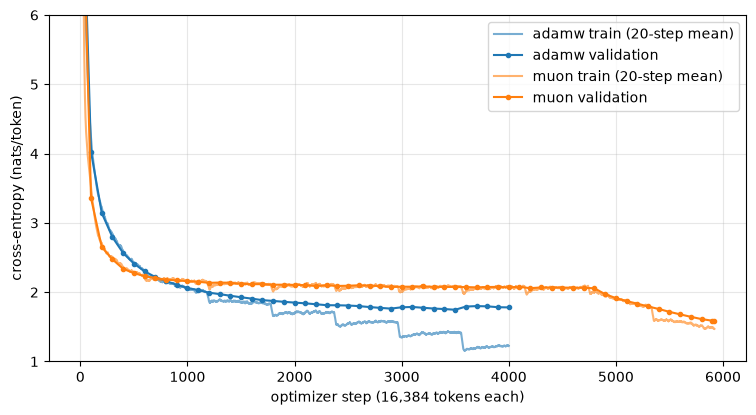

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name in finals:
    rows = [json.loads(l) for l in open(RUNS / "final" / name / "metrics.jsonl")]
    t = pd.DataFrame([r for r in rows if r.get("train_loss") is not None])
    v = pd.DataFrame([r for r in rows if "val_loss" in r])
    line, = ax.plot(t.step, t.train_loss.rolling(20, min_periods=1).mean(), alpha=0.6, label=f"{name} train (20-step mean)")
    ax.plot(v.step, v.val_loss, "o-", color=line.get_color(), ms=3, label=f"{name} validation")
ax.set(xlabel="optimizer step (16,384 tokens each)", ylabel="cross-entropy (nats/token)", ylim=(1, 6))
ax.legend(); ax.grid(alpha=0.3); plt.show()

In [8]:
pd.DataFrame(finals).T[["optim", "sched", "lr", "wd", "steps", "best_step", "stopped_early", "best_val_loss",
                        "full_val_loss", "full_val_bpb", "elapsed_min"]]

,optim,sched,lr,wd,steps,best_step,stopped_early,best_val_loss,full_val_loss,full_val_bpb,elapsed_min
adamw,adamw,cosine,0.0005,1.0,4000,3500,True,1.746581,1.731429,0.604565,91.075825
muon,muon,wsd,0.004,1.0,5920,5920,False,1.587212,1.573775,0.549517,152.481227


## 5. Generation at temperatures 0.5, 0.8, 1.0, 1.2 (max 30 new tokens)

Text is lowercased with apostrophes removed before tokenization (`DECISIONS.md` §2), so the
model writes in lowercase.

In [9]:
for name in finals:
    print(f"==================== {name} ====================")
    model, tok = load_model(RUNS / "final" / name / "best.pt")
    model.eval()
    print(format_generations(model, tok, SPEC_PROMPTS, SPEC_TEMPERATURES, seed=0))

==================== adamw ====================


📝 Testing prompt: 'Once upon a time'
----------------------------------------
  Stopped after maximum 30 tokens
Temperature 0.5: 'once upon a time, there was a little girl named lily. she loved to play outside in the sunshine. one day, she went to the park with her mom and'

  Stopped after maximum 30 tokens
Temperature 0.8: 'once upon a time there was a brave little girl called lucy. every day she would try new games like playing games and working hard.

one day, lucy wanted'

  Stopped after maximum 30 tokens
Temperature 1.0: 'once upon a time, there was a very special girl named amy. so she wasnâ€™t only three years old, but she was curious about the world. every week'

  Stopped after maximum 30 tokens
Temperature 1.2: 'once upon a time, there lived a great elderly lady who lived in a big village. she had lots of fruits and vegetables in her big collection. one day, she'

📝 Testing prompt: 'The little dog'
----------------------------------------
  Stopped after maximum 30 tokens
T

📝 Testing prompt: 'Once upon a time'
----------------------------------------
  Stopped after maximum 30 tokens
Temperature 0.5: 'once upon a time, there was a little girl named lily. she loved to play outside in the sun. one day, she saw a big, bright sun in the'

  Stopped after maximum 30 tokens
Temperature 0.8: 'once upon a time there was a brave prince. he wanted to see what the world had to offer. so he set off on a journey. he walked and walked until'

  Stopped after maximum 30 tokens
Temperature 1.0: 'once upon a time, there was a very special place. on this so special place that was the most beautiful place in the world. 
one day, a little'

  Stopped after maximum 30 tokens
Temperature 1.2: 'once upon a time, there lived a great elderly lady who loved her phone very much. she used it kindly so everyone could hear her. 
one day, she'

📝 Testing prompt: 'The little dog'
----------------------------------------
  Stopped after maximum 30 tokens
Temperature 0.5: 'the little dog 

## 6. Sentiment classifier on our model, graded against `emotions_classified.csv`

The classifier is our pretrained Qwen3_small with a linear head on the last token's hidden
state. Graded on the CSV's `sentiment` column on a held-out stratified test split (10%, never
used for training or model selection); the 6-class `emotion` column is a secondary result.

In [10]:
base = json.loads((RUNS / "cls" / "baselines.json").read_text())
rows = [{"model": "majority class", "label": "sentiment", **base["sentiment_majority"]},
        {"model": "TF-IDF + logistic regression", "label": "sentiment", **base["sentiment_tfidf_lr"]}]
results = {p.parent.name: json.loads(p.read_text()) for p in sorted((RUNS / "cls").glob("*/result.json"))}
for name, r in results.items():
    rows.append({"model": f"Qwen3_small {r['mode']} ({r['pool']} pool)", "label": r["label"],
                 "test_acc": r["test_acc"], "test_macro_f1": r["test_macro_f1"]})
rows += [{"model": "majority class", "label": "emotion", **base["emotion_majority"]},
         {"model": "TF-IDF + logistic regression", "label": "emotion", **base["emotion_tfidf_lr"]}]
pd.DataFrame(rows).sort_values("label", kind="stable").round(4)

,model,label,test_acc,test_macro_f1
2,Qwen3_small full (last pool),emotion,0.9280,0.9044
7,majority class,emotion,0.3350,0.0836
8,TF-IDF + logistic regression,emotion,0.8660,0.8409
0,majority class,sentiment,0.5485,0.3542
1,TF-IDF + logistic regression,sentiment,0.9386,0.9380
3,Qwen3_small full (last pool),sentiment,0.9737,0.9735
4,Qwen3_small full (mean pool),sentiment,0.9674,0.9671
5,Qwen3_small probe (last pool),sentiment,0.7220,0.7195
6,Qwen3_small random (last pool),sentiment,0.9474,0.9469


In [11]:
main = results["sentiment_full_last"]
print(f"Test accuracy {main['test_acc']:.4f} | macro-F1 {main['test_macro_f1']:.4f}\n")
print(pd.DataFrame(main["report"]).T.round(4))
cm = pd.DataFrame(main["confusion"], index=[f"true {c}" for c in main["classes"]],
                  columns=[f"pred {c}" for c in main["classes"]])
cm

Test accuracy 0.9737 | macro-F1 0.9735

              precision  recall  f1-score    support
negative         0.9771  0.9749    0.9760   876.0000
positive         0.9696  0.9723    0.9709   721.0000
accuracy         0.9737  0.9737    0.9737     0.9737
macro avg        0.9733  0.9736    0.9735  1597.0000
weighted avg     0.9737  0.9737    0.9737  1597.0000


,pred negative,pred positive
true negative,854,22
true positive,20,701


In [12]:
if "emotion_full_last" in results:
    e = results["emotion_full_last"]
    print(f"emotion (6-class): test accuracy {e['test_acc']:.4f} | macro-F1 {e['test_macro_f1']:.4f}")
    display(pd.DataFrame(e["confusion"], index=e["classes"], columns=e["classes"]))

emotion (6-class): test accuracy 0.9280 | macro-F1 0.9044


,anger,fear,joy,love,sadness,surprise
anger,194,5,7,0,10,0
fear,8,168,2,0,8,7
joy,5,1,491,27,7,4
love,0,1,7,121,0,1
sadness,4,2,2,1,458,0
surprise,0,3,2,0,1,50
